# Decision Trees: Information Gain

## 1. Write the dataset to disk
The following is a Colab/Jupyter magic command. It creates `weather.csv` in the notebook working directory.

In [1]:
%%writefile weather.csv
Outlook,Temperature,Humidity,Windy,Play Outside
Sunny,Hot,High,False,No
Sunny,Hot,High,True,No
Overcast,Hot,High,False,Yes
Rainy,Mild,High,False,Yes
Rainy,Cool,Normal,False,Yes
Rainy,Cool,Normal,True,No
Overcast,Cool,Normal,True,Yes
Sunny,Mild,High,False,No
Sunny,Cool,Normal,False,Yes
Rainy,Mild,Normal,False,Yes
Sunny,Mild,Normal,True,Yes
Overcast,Mild,High,True,Yes
Overcast,Hot,Normal,False,Yes
Rainy,Mild,High,True,No

Writing weather.csv


## 2. Read and inspect the data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.preprocessing import OneHotEncoder

weather = pd.read_csv("weather.csv")
display(weather)
print("Class counts:")
print(weather["Play Outside"].value_counts())

,Outlook,Temperature,Humidity,Windy,Play Outside
0,Sunny,Hot,High,False,No
1,Sunny,Hot,High,True,No
2,Overcast,Hot,High,False,Yes
3,Rainy,Mild,High,False,Yes
4,Rainy,Cool,Normal,False,Yes
5,Rainy,Cool,Normal,True,No
6,Overcast,Cool,Normal,True,Yes
7,Sunny,Mild,High,False,No
8,Sunny,Cool,Normal,False,Yes
9,Rainy,Mild,Normal,False,Yes


Class counts:
Play Outside
Yes    9
No     5
Name: count, dtype: int64


## 3. Train a decision tree using scikit-learn

We use **one-hot encoding** for the categorical inputs. This is important: sklearn's tree splits are **binary** (for example, `Outlook_Overcast <= 0.5`), whereas the hand calculation below considers a **multiway** question with one branch per category (`Sunny`, `Overcast`, `Rainy`). Therefore, the root gain in sklearn may differ from the manual multiway Outlook gain, and that's expected.

Training accuracy: 1.0
Root feature: Outlook_Overcast


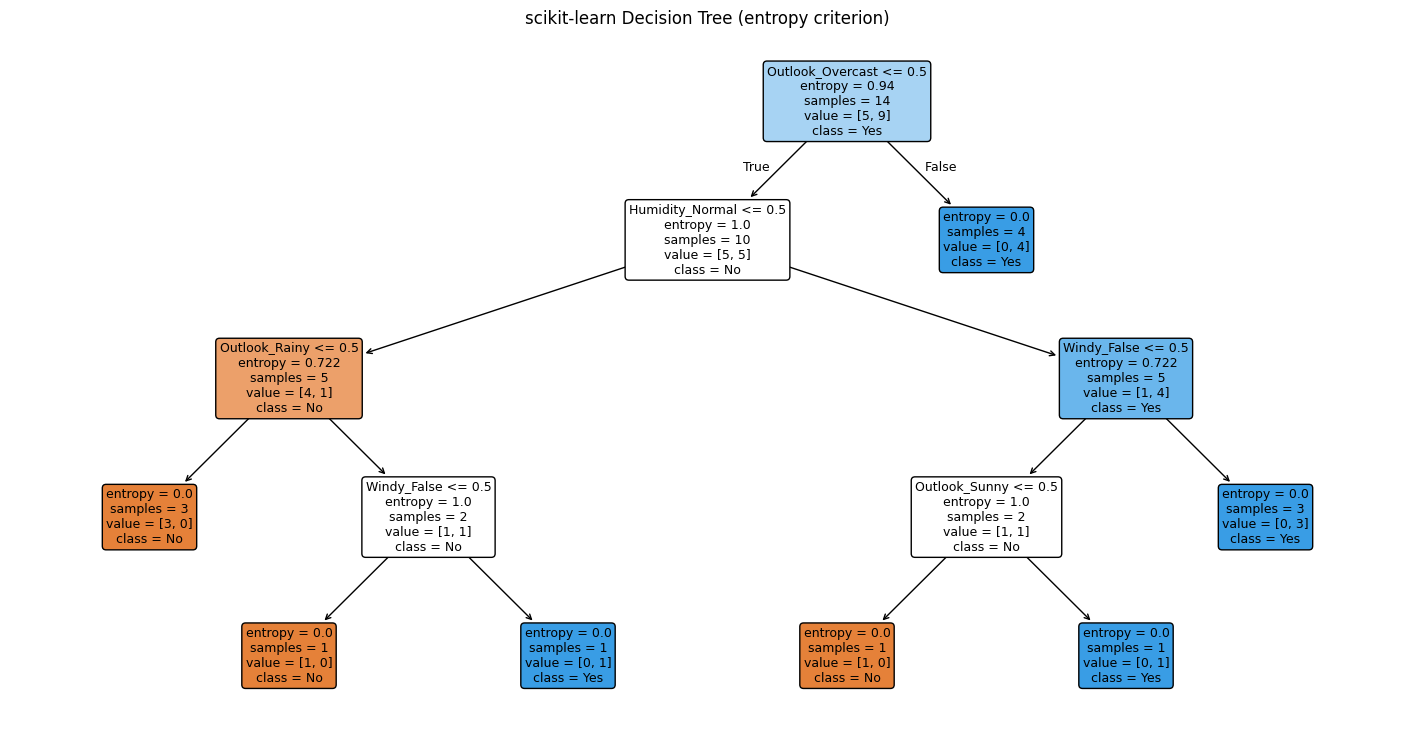

In [3]:
X = weather.drop(columns="Play Outside")
y = weather["Play Outside"]

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_encoded = encoder.fit_transform(X)
feature_names = encoder.get_feature_names_out(X.columns)

clf = DecisionTreeClassifier(criterion="entropy", random_state=42)
clf.fit(X_encoded, y)

print("Training accuracy:", clf.score(X_encoded, y))
print("Root feature:", feature_names[clf.tree_.feature[0]])

plt.figure(figsize=(18, 9))
plot_tree(clf, feature_names=feature_names,
          class_names=clf.classes_, filled=True, rounded=True,
          impurity=True, proportion=False, fontsize=9)
plt.title("scikit-learn Decision Tree (entropy criterion)")
plt.show()

## 4. Information Gain from the trained sklearn tree

The sklearn `tree_` object exposes **entropy** (`impurity`), node sample counts, child nodes, and split features. For a node, we compute its **information gain** from those sklearn-reported quantities:

\[IG=H(\text{parent})-\frac{n_L}{n}H(L)-\frac{n_R}{n}H(R)\]

The values below are **local gains for binary splits actually chosen by sklearn**, not a score for every possible original feature.

In [4]:
t = clf.tree_
rows = []
for node in range(t.node_count):
    left, right = t.children_left[node], t.children_right[node]
    if left == _tree.TREE_LEAF:
        continue
    n = t.weighted_n_node_samples[node]
    nl = t.weighted_n_node_samples[left]
    nr = t.weighted_n_node_samples[right]
    gain = t.impurity[node] - (nl/n)*t.impurity[left] - (nr/n)*t.impurity[right]
    rows.append({
        "node": node,
        "binary question": feature_names[t.feature[node]],
        "samples": int(t.n_node_samples[node]),
        "entropy before": round(t.impurity[node], 4),
        "entropy after": round((nl/n)*t.impurity[left] + (nr/n)*t.impurity[right], 4),
        "information gain": round(gain, 4)
    })
node_gains = pd.DataFrame(rows)
display(node_gains)
print("Root binary split information gain:", node_gains.iloc[0]["information gain"])
print("sklearn feature_importances_ (normalized, aggregated over the tree):")
display(pd.Series(clf.feature_importances_, index=feature_names).sort_values(ascending=False).to_frame("importance"))

,node,binary question,samples,entropy before,entropy after,information gain
0,0,Outlook_Overcast,14,0.9403,0.7143,0.2260
1,1,Humidity_Normal,10,1.0000,0.7219,0.2781
2,2,Outlook_Rainy,5,0.7219,0.4000,0.3219
3,4,Windy_False,2,1.0000,0.0000,1.0000
4,7,Windy_False,5,0.7219,0.4000,0.3219
5,8,Outlook_Sunny,2,1.0000,0.0000,1.0000


Root binary split information gain: 0.226
sklearn feature_importances_ (normalized, aggregated over the tree):


,importance
Windy_False,0.274205
Outlook_Overcast,0.240353
Humidity_Normal,0.211237
Outlook_Sunny,0.151929
Outlook_Rainy,0.122276
Temperature_Cool,0.000000
Temperature_Mild,0.000000
Temperature_Hot,0.000000
Humidity_High,0.000000
Windy_True,0.000000


In [6]:
# Extract feature name from binary question
df = node_gains.copy()
df["feature"] = df["binary question"].str.split("_").str[0]

# Weighted information gain
total_samples = df.loc[df["node"] == 0, "samples"].iloc[0]

df["weighted_gain"] = (
    df["samples"] / total_samples
) * df["information gain"]

# Aggregate by feature
feature_importance = df.groupby("feature")["weighted_gain"].sum()

# Normalize
feature_importance = (
    feature_importance / feature_importance.sum()
).sort_values(ascending=False)

print(feature_importance)

feature
Outlook     0.514547
Windy       0.274195
Humidity    0.211258
Name: weighted_gain, dtype: float64


## 5. Manually calculate entropy

For class labels Yes and No:

\[H(Y)=-p_{Yes}\log_2(p_{Yes})-p_{No}\log_2(p_{No})\]

We use the actual label counts. A pure group has entropy 0.

In [7]:
from math import log2

def entropy(labels):
    counts = pd.Series(labels).value_counts()
    probabilities = counts / counts.sum()
    return -sum(p * log2(p) for p in probabilities if p > 0)

base_entropy = entropy(y)
print("Yes =", (y == "Yes").sum(), "No =", (y == "No").sum())
print(f"H(Play Outside) = -9/14 log2(9/14) - 5/14 log2(5/14) = {base_entropy:.6f} bits")

Yes = 9 No = 5
H(Play Outside) = -9/14 log2(9/14) - 5/14 log2(5/14) = 0.940286 bits


## 6. Manually calculate the first question: Humidity

Humidity has two branches: Normal and High. Calculate the entropy of each branch and their weighted average, then subtract from the starting entropy.

In [8]:
feature = "Humidity"
weighted_after = 0.0
for value, subset in weather.groupby(feature):
    branch_entropy = entropy(subset["Play Outside"])
    weight = len(subset) / len(weather)
    weighted_after += weight * branch_entropy
    print(f"{value:7s}: {len(subset)} rows, "
          f"Yes={(subset['Play Outside']=='Yes').sum()}, "
          f"No={(subset['Play Outside']=='No').sum()}, "
          f"H={branch_entropy:.6f}, weight={weight:.3f}")
print(f"\nEntropy before = {base_entropy:.6f}")
print(f"Weighted entropy after = {weighted_after:.6f}")
print(f"Information Gain(Humidity) = {base_entropy:.6f} - {weighted_after:.6f} = {base_entropy-weighted_after:.6f}")

High   : 7 rows, Yes=3, No=4, H=0.985228, weight=0.500
Normal : 7 rows, Yes=6, No=1, H=0.591673, weight=0.500

Entropy before = 0.940286
Weighted entropy after = 0.788450
Information Gain(Humidity) = 0.940286 - 0.788450 = 0.151836


## 7. Manually evaluate *every* possible first question

For each original categorical feature, split into **all** its categories and calculate:

\[IG(Y, X)=H(Y)-\sum_{v \in X}\frac{|S_v|}{|S|}H(Y\mid X=v)\]

The feature with the largest Information Gain is the best first question **for a multiway categorical decision tree**.

,Question,Entropy before,Weighted entropy after,Information Gain
0,Outlook,0.9403,0.6935,0.2467
2,Humidity,0.9403,0.7885,0.1518
3,Windy,0.9403,0.8922,0.0481
1,Temperature,0.9403,0.9111,0.0292


BEST FIRST QUESTION: Outlook (IG = 0.246750)

Detailed calculation for the winner:
  Overcast: n=4, weight=0.286, entropy=-0.000000
  Rainy: n=5, weight=0.357, entropy=0.970951
  Sunny: n=5, weight=0.357, entropy=0.970951


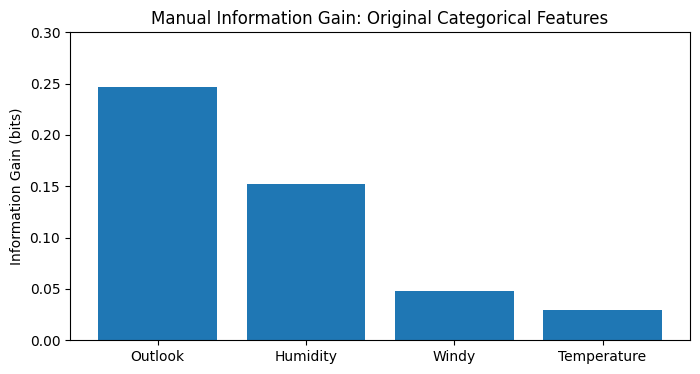

In [9]:
def manual_information_gain(df, feature, target="Play Outside", verbose=False):
    before = entropy(df[target])
    after = 0.0
    for category, subset in df.groupby(feature):
        weight = len(subset) / len(df)
        h = entropy(subset[target])
        after += weight * h
        if verbose:
            print(f"  {category}: n={len(subset)}, weight={weight:.3f}, entropy={h:.6f}")
    return before, after, before - after

scores = []
for feature in X.columns:
    before, after, gain = manual_information_gain(weather, feature)
    scores.append({"Question": feature,
                   "Entropy before": before,
                   "Weighted entropy after": after,
                   "Information Gain": gain})

score_table = pd.DataFrame(scores).sort_values("Information Gain", ascending=False)
display(score_table.style.format({"Entropy before":"{:.4f}",
                                  "Weighted entropy after":"{:.4f}",
                                  "Information Gain":"{:.4f}"}))

best = score_table.iloc[0]
print(f"BEST FIRST QUESTION: {best['Question']} (IG = {best['Information Gain']:.6f})")
print("\nDetailed calculation for the winner:")
manual_information_gain(weather, best["Question"], verbose=True)

plt.figure(figsize=(8,4))
plt.bar(score_table["Question"], score_table["Information Gain"])
plt.title("Manual Information Gain: Original Categorical Features")
plt.ylabel("Information Gain (bits)")
plt.ylim(0, 0.30)
plt.show()